In [1]:
!nvidia-smi

Wed Nov 25 12:04:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import os
os.chdir('/content/drive/MyDrive/project_football_WorldCup2026')

In [ ]:
!pip install -q ultralytics roboflow supervision

In [ ]:
!pip install "supervision<0.31.0"

kaggle 에서 주최한 DFL 분데스리가 데이터 슈팅 대회에서 가져옴. 이번 대회의 일환으로 주최측은 20경기에서 발췌한 약 80개의 30초 분량 영상을 공개함.

이 데이터를 활용하여 객체 탐지 및 특징점 탐지 모델을 더욱 정밀하게 조정할 것임.

문제 정의 -> 데이터 수집 -> 데이터 전처리 -> 모델 학습 -> 모델 평가 -> 모델 배포

In [ ]:
# # 잘 동작 하는지 확인

# from ultralytics import YOLO
# model = YOLO('yolov8m')

# result = model.predict('08fd33_4.mp4', save=True)
# print(result[0])
# print('====================')
# for box in result[0].boxes:
#   print(box)

In [ ]:
# # roboflow 에서 데이터 가져옴. 실행하기 위해서 파일 위치를 옮겨야함.

# from roboflow import Roboflow
# rf = Roboflow(api_key="zUjuyJm25IqTd29mZ8CE")
# project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
# version = project.version(1)
# dataset = version.download("yolov5")

# import shutil
# shutil.move('football-players-detection-1/train',
#             'football-players-detection-1/football-players-detection-1/train')
# shutil.move('football-players-detection-1/test',
#             'football-players-detection-1/football-players-detection-1/test')
# shutil.move('football-players-detection-1/valid',
#             'football-players-detection-1/football-players-detection-1/valid')

loading Roboflow workspace...
loading Roboflow project...


# 이걸 통해서 best.pt를 다운받으면 그걸로 개인컴퓨터에서 실행가능

In [ ]:
# from roboflow import Roboflow
# from ultralytics import YOLO

# !yolo task=detect mode=train model=yolov5m.pt data={dataset.location}/data.yaml epochs=100 imgsz=640

PRO TIP 💡 Replace 'model=yolov5m.pt' with new 'model=yolov5mu.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.
Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/project_football_WorldCup2026/football-players-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None

In [ ]:
# import shutil

# shutil.copy('runs/detect/train/weights/best.pt',
#                  'models/best.pt')

'models/best.pt'

# 내가 녹화해서 분석할수있는 코드

In [ ]:
!python -u main.py


/content/drive/MyDrive/project_football_WorldCup2026/trackers/tracker.py:15: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack()
frame count check: 240 240 240


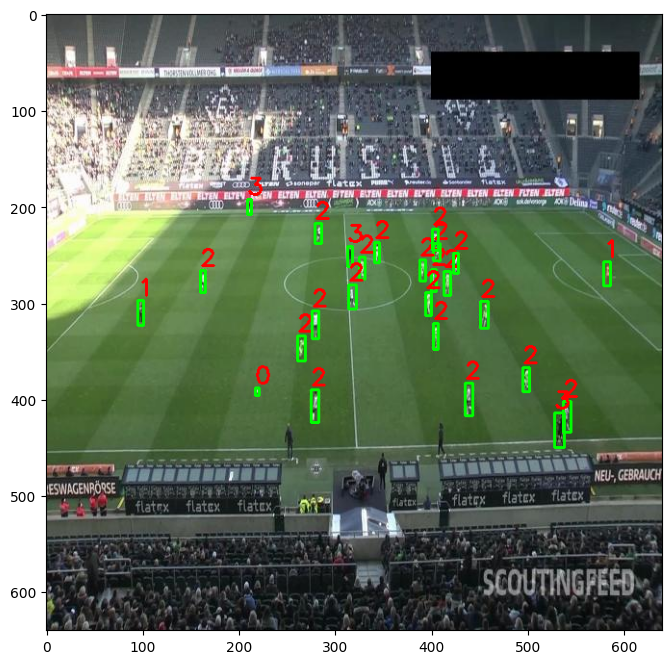

In [ ]:
# # 기존 데이터셋에 라벨링이 숫자로 되어있어서 숫자가 어떤걸 의미하는지 직접 확인
# # {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}
# import cv2
# import matplotlib.pyplot as plt

# img_path = 'Football-Player-1/Football-Player-1/train/images/08fd33_0_1_png_jpg.rf.81e41b4bb6d485b5def5f7a75592acfc.jpg'
# label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')

# img = cv2.imread(img_path)
# h, w = img.shape[:2]

# with open(label_path, 'r') as f:
#     for line in f.readlines():
#         cls_id, xc, yc, bw, bh = map(float, line.split())
#         cls_id = int(cls_id)
#         x1 = int((xc - bw/2) * w)
#         y1 = int((yc - bh/2) * h)
#         x2 = int((xc + bw/2) * w)
#         y2 = int((yc + bh/2) * h)
#         cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
#         cv2.putText(img, str(cls_id), (x1,y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,0,255), 2)

# plt.figure(figsize=(12,8))
# plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
# plt.show()

In [ ]:
# !pip install -q -U "yt-dlp[default]"
# !curl -fsSL https://deno.land/install.sh | sh

# import os
# os.environ["PATH"] = (
#     os.path.expanduser("~/.deno/bin")
#     + os.pathsep
#     + os.environ["PATH"]
# )

# !deno --version
# !ffmpeg -version

In [ ]:
# import os

# save_dir = "/content/drive/MyDrive/project_football_WorldCup2026/input_videos"
# os.makedirs(save_dir, exist_ok=True)

# output_path = f"{save_dir}/clip_0127_0131.mp4"

# !yt-dlp \
#     --js-runtimes deno \
#     --download-sections "*00:00:00-00:01:50" \
#     --force-keyframes-at-cuts \
#     -f "bv*+ba/b" \
#     --merge-output-format mp4 \
#     -o "{output_path}" \
#     "https://www.youtube.com/watch?v=6k18EJY8zIc"

# if os.path.exists(output_path):
#     print("다운로드 성공:", output_path)
# else:
#     print("다운로드 실패: 위 yt-dlp 오류 확인 필요")

In [ ]:
import json, os, shutil

coco_valid_dir = "/content/drive/MyDrive/project_football_WorldCup2026/input_videos/2026worldcup kor vs cze-Uploaded on 11-22-26 at 8-57 pm - Auto Label.coco/valid"
json_path = os.path.join(coco_valid_dir, "_annotations.coco.json")

out_root = "/content/kor_cze_val_yolo"
img_out = os.path.join(out_root, "images/val")
lbl_out = os.path.join(out_root, "labels/val")
os.makedirs(img_out, exist_ok=True)
os.makedirs(lbl_out, exist_ok=True)

with open(json_path, "r") as f:
    coco = json.load(f)

# COCO id(1~4) -> 기존 best.pt id(0~3) 매핑
cat_map = {1: 0, 2: 1, 3: 2, 4: 3}  # ball, goalkeeper, player, referee
img_info = {im["id"]: im for im in coco["images"]}
anns_by_img = {im["id"]: [] for im in coco["images"]}

for ann in coco["annotations"]:
    if ann["category_id"] in cat_map:
        anns_by_img[ann["image_id"]].append(ann)

count = 0
for img_id, info in img_info.items():
    fname = info["file_name"]
    src_img = os.path.join(coco_valid_dir, fname)
    if not os.path.exists(src_img):
        continue
    shutil.copy2(src_img, os.path.join(img_out, fname))
    w, h = info["width"], info["height"]
    stem = os.path.splitext(fname)[0]
    lines = []
    for ann in anns_by_img[img_id]:
        x, y, bw, bh = ann["bbox"]
        xc = (x + bw / 2) / w
        yc = (y + bh / 2) / h
        lines.append(f"{cat_map[ann['category_id']]} {xc:.6f} {yc:.6f} {bw/w:.6f} {bh/h:.6f}")
    with open(os.path.join(lbl_out, f"{stem}.txt"), "w") as lf:
        lf.write("\n".join(lines))
    count += 1

yaml_text = f"""path: {out_root}
train: images/val
val: images/val
names:
  0: ball
  1: goalkeeper
  2: player
  3: referee
"""
with open(os.path.join(out_root, "data.yaml"), "w") as yf:
    yf.write(yaml_text)

print(f"변환 완료: 총 {count}장 -> {out_root}/data.yaml")

변환 완료: 총 55장 -> /content/kor_cze_val_yolo/data.yaml


In [ ]:
!yolo detect val \
    model="/content/drive/MyDrive/project_football_WorldCup2026/models/best.pt" \
    data="/content/kor_cze_val_yolo/data.yaml" \
    imgsz=640 \
    project="/content/drive/MyDrive/project_football_WorldCup2026/runs/val_kor_cze" \
    name="yolov5m_eval"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5m summary (fused): 107 layers, 25,047,532 parameters, 0 gradients, 64.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3162.5±984.7 MB/s, size: 387.1 KB)
val: Scanning /content/kor_cze_val_yolo/labels/val... 55 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 931.2it/s 0.1s
val: New cache created: /content/kor_cze_val_yolo/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3it/s 3.0s
                   all         55        811        0.7      0.541      0.552       0.39
                  ball         34         3

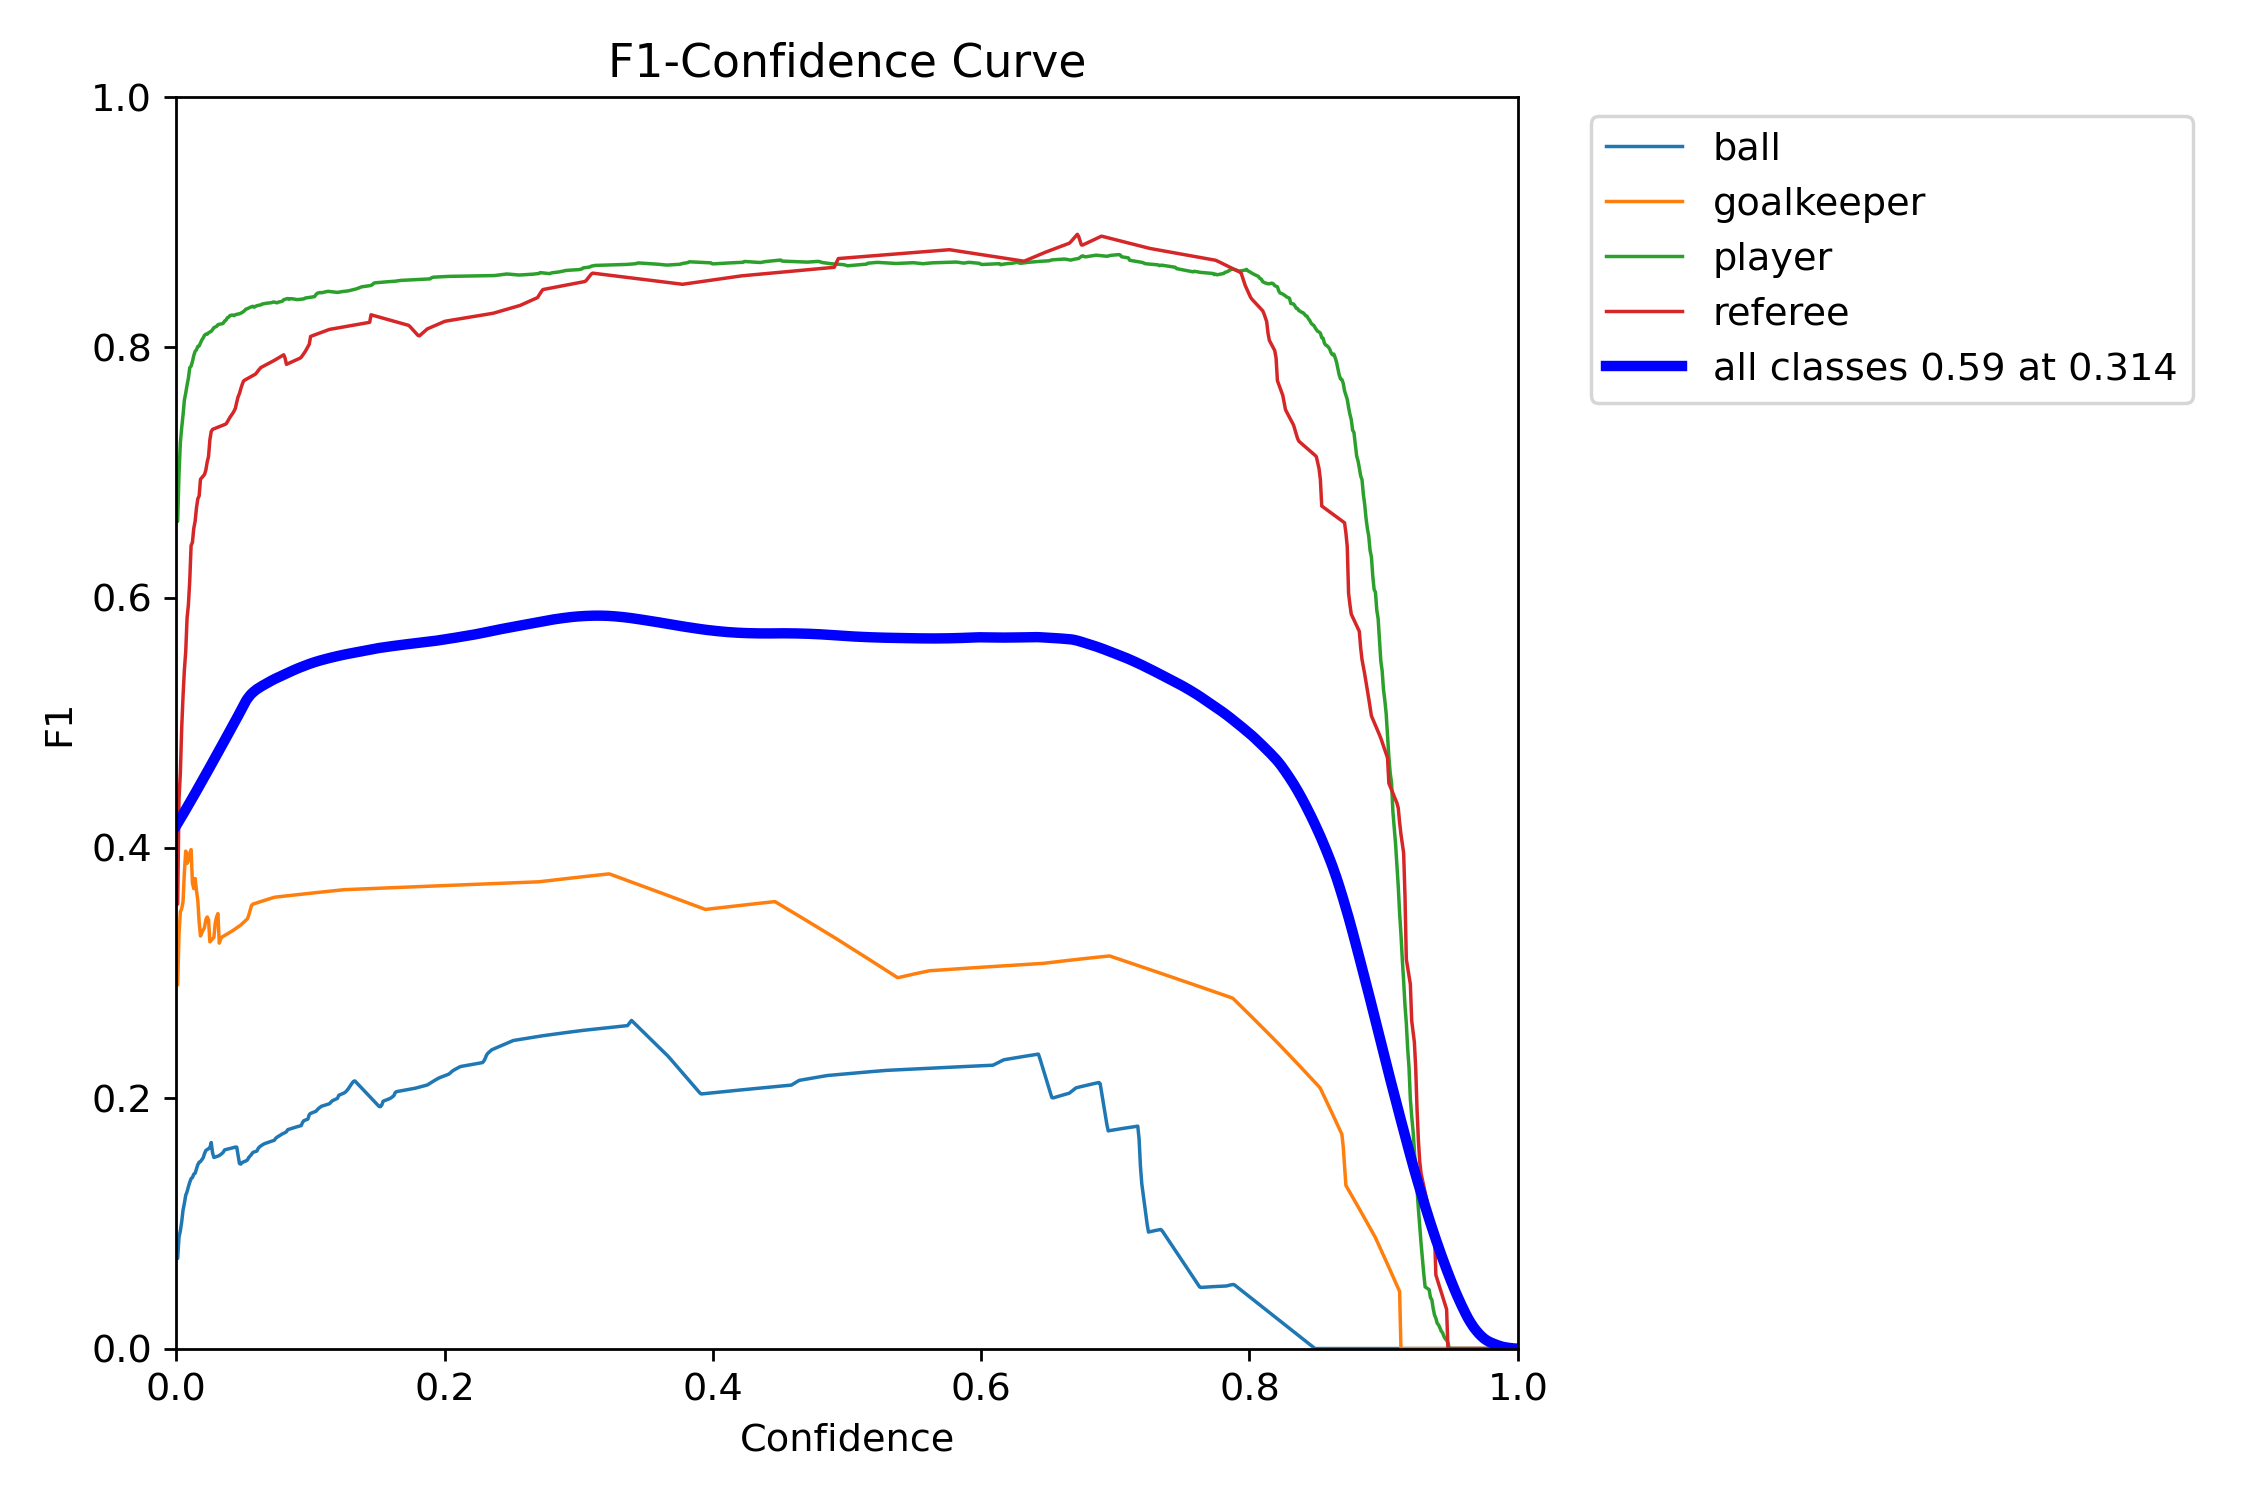

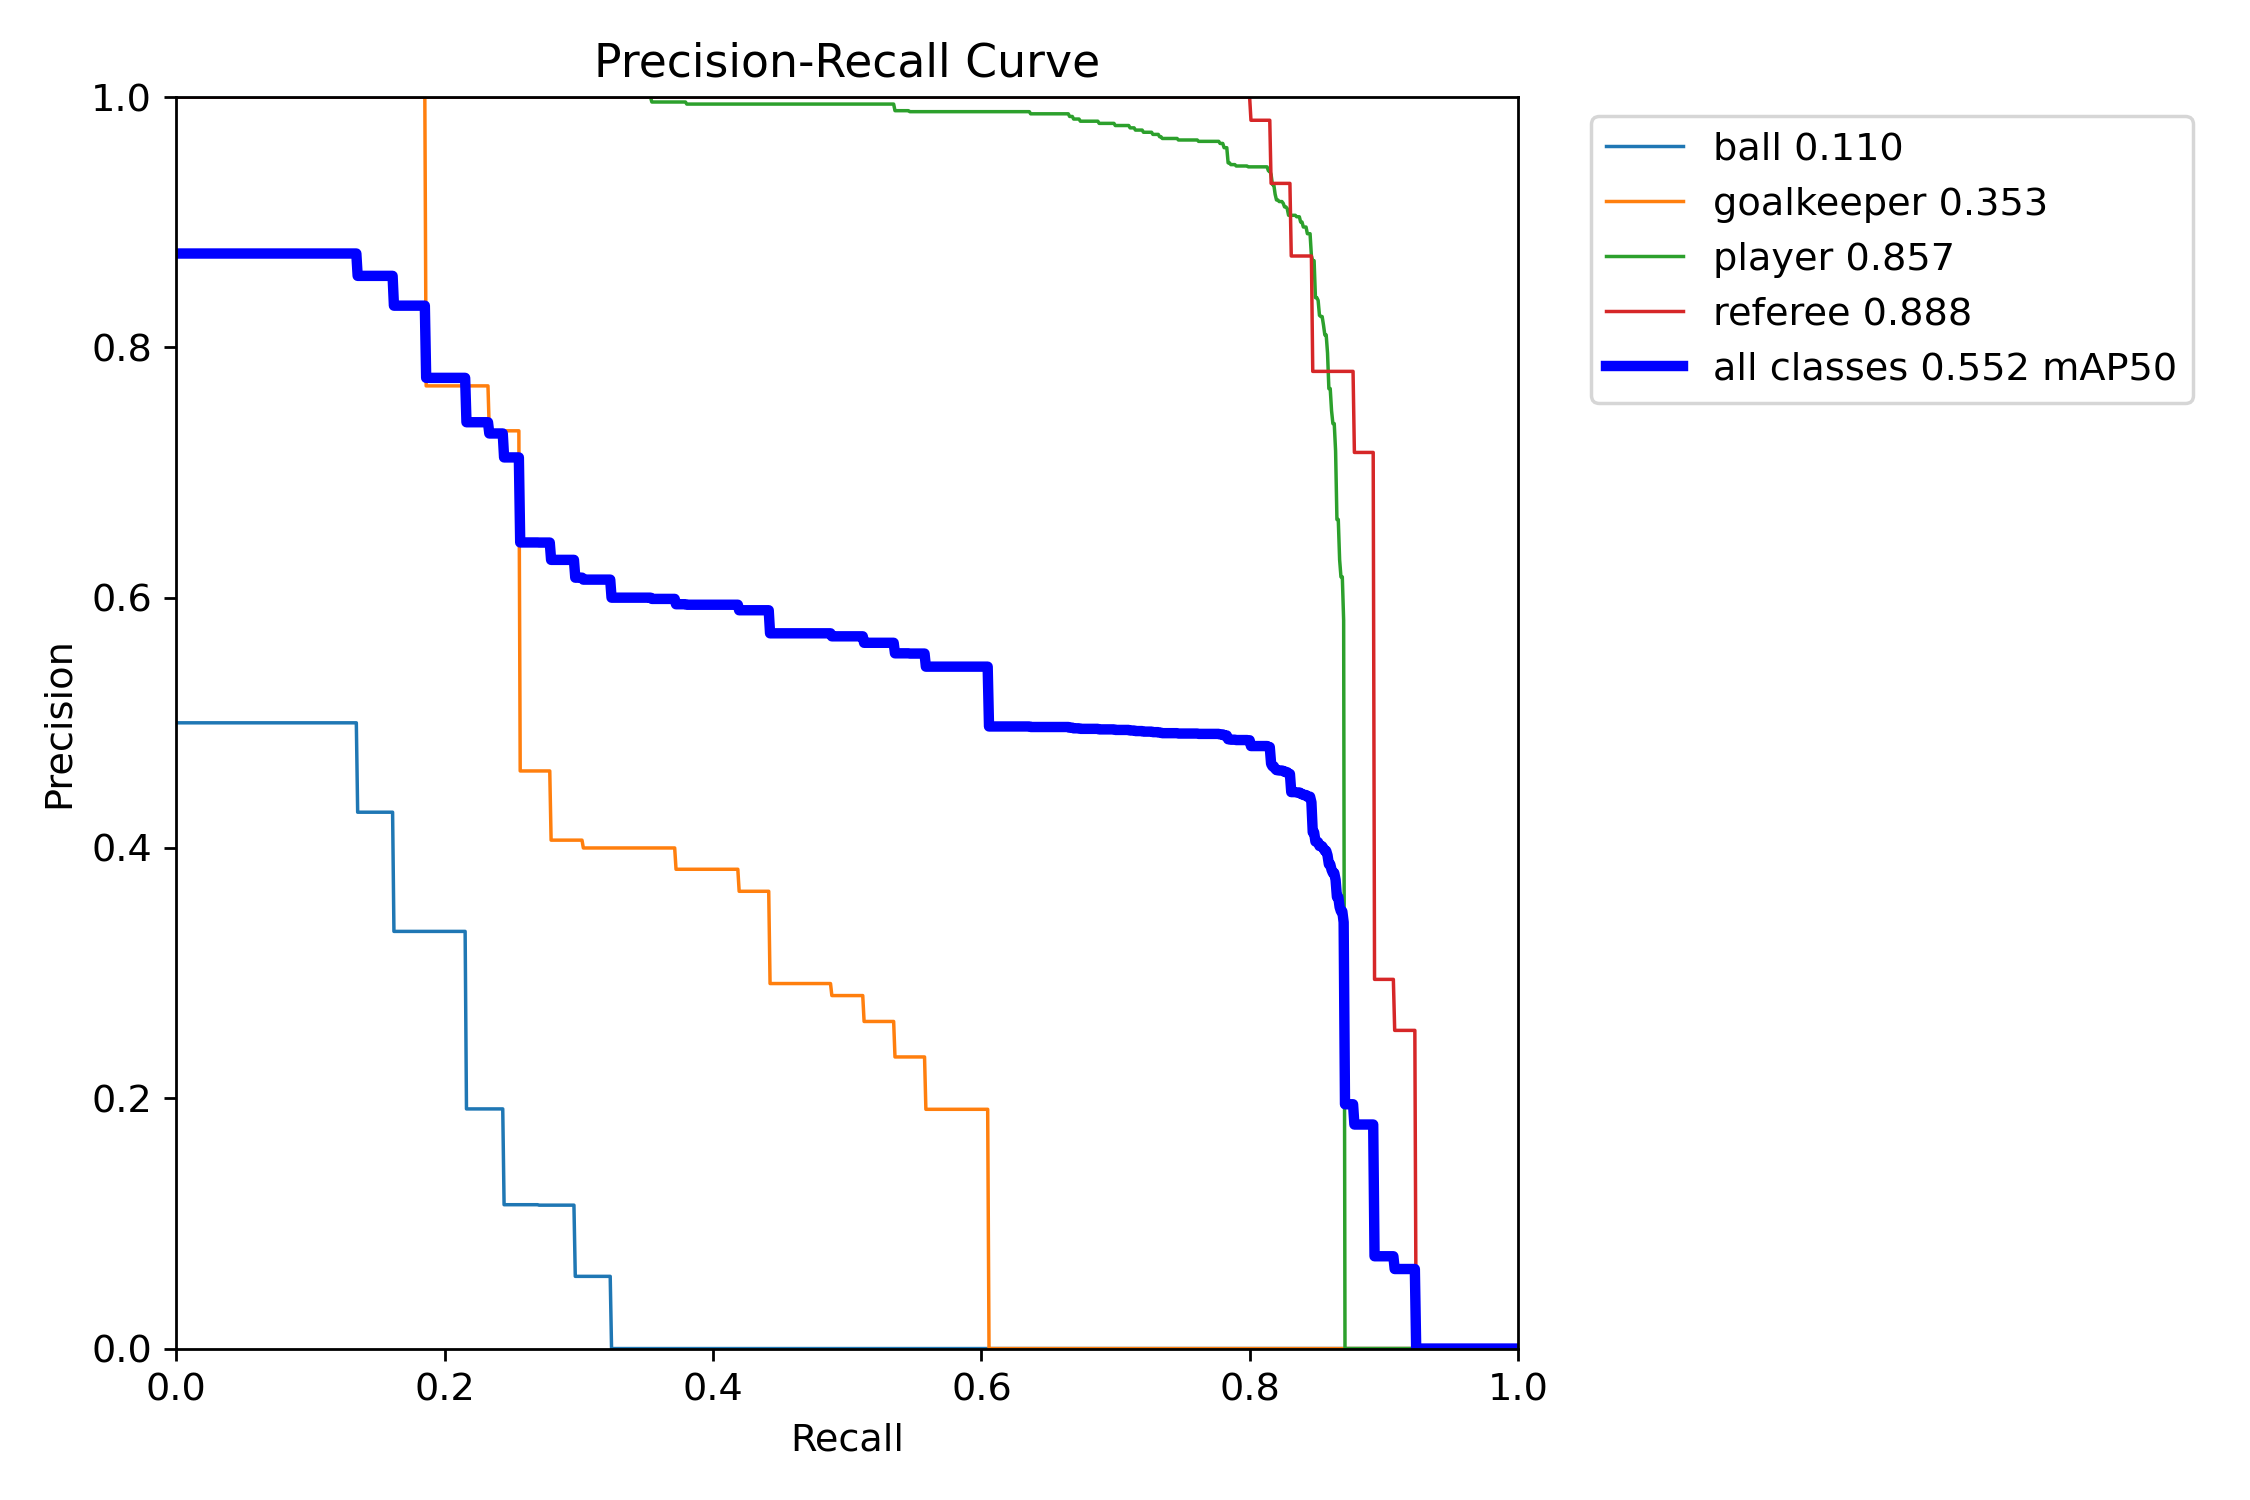

In [ ]:
from IPython.display import Image, display

eval_dir = "/content/drive/MyDrive/project_football_WorldCup2026/runs/val_kor_cze/yolov5m_eval"
display(Image(filename=f"{eval_dir}/BoxF1_curve.png", width=650))
display(Image(filename=f"{eval_dir}/BoxPR_curve.png", width=650))

In [ ]:
!yolo detect val \
    model="/content/drive/MyDrive/project_football_WorldCup2026/models/best.pt" \
    data="/content/kor_cze_val_yolo/data.yaml" \
    imgsz=1280 \
    project="/content/drive/MyDrive/project_football_WorldCup2026/runs/val_kor_cze" \
    name="yolov5m_1280_eval"

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5m summary (fused): 107 layers, 25,047,532 parameters, 0 gradients, 64.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3032.1±856.3 MB/s, size: 364.7 KB)
val: Scanning /content/kor_cze_val_yolo/labels/val.cache... 55 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 12.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0it/s 3.9s
                   all         55        811      0.397      0.445      0.419      0.269
                  ball         34         37      0.331      0.297      0.192     0.0886
            goalkeeper         42         43     0.0846     0.0465     0.0127     0.0065
                player         53        666       0.62      0.788      0.778      0.535
               referee         41         65      0.553      0.646      0.693      0.445
Speed: 6.6ms preprocess, 40.7ms inferenc

In [ ]:
!pip install -q -U ultralytics roboflow

import os
from roboflow import Roboflow

os.chdir("/content")

# 기존 노트북 8번 셀에 있던 본인의 Roboflow API Key 입력
rf = Roboflow(api_key="zUjuyJm25IqTd29mZ8CE")
project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
dataset = project.version(1).download("yolov8")  # YOLO26/11 모두 표준 YOLO 포맷 그대로 사용

# YOLO26m + 고해상도 1280 학습 (소형 객체 ball 탐지 강화)
!yolo detect train \
    model=yolo26m.pt \
    data="{dataset.location}/data.yaml" \
    epochs=60 \
    imgsz=1280 \
    batch=-1 \
    cos_lr=True \
    close_mosaic=10 \
    patience=15 \
    project="/content/drive/MyDrive/project_football_WorldCup2026/runs/train_yolo26m" \
    name="yolo26m_1280"

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-1 in yolov8:: 100%|██████████| 1338/1338 [00:00<00:00, 2354.79it/s]


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/football-players-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m_1280, nbs=64, nms=None, opset=Non

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,352,536 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2486.1±601.4 MB/s, size: 277.3 KB)
val: Scanning /content/kor_cze_val_yolo/labels/val.cache... 55 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 9.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1s/it 4.5s
                   all         55        811      0.768      0.689      0.662      0.485
                  ball         34         37      0.466      0.676      0.397      0.209
            goalkeeper         42         43      0.874      0.324      0.445      0.337
                player         53        666      0.887      0.866      0.881      0.694
               referee         41         65      0.845      0.892      0.925      0.699
Speed: 6.2ms preprocess, 55.2ms inference

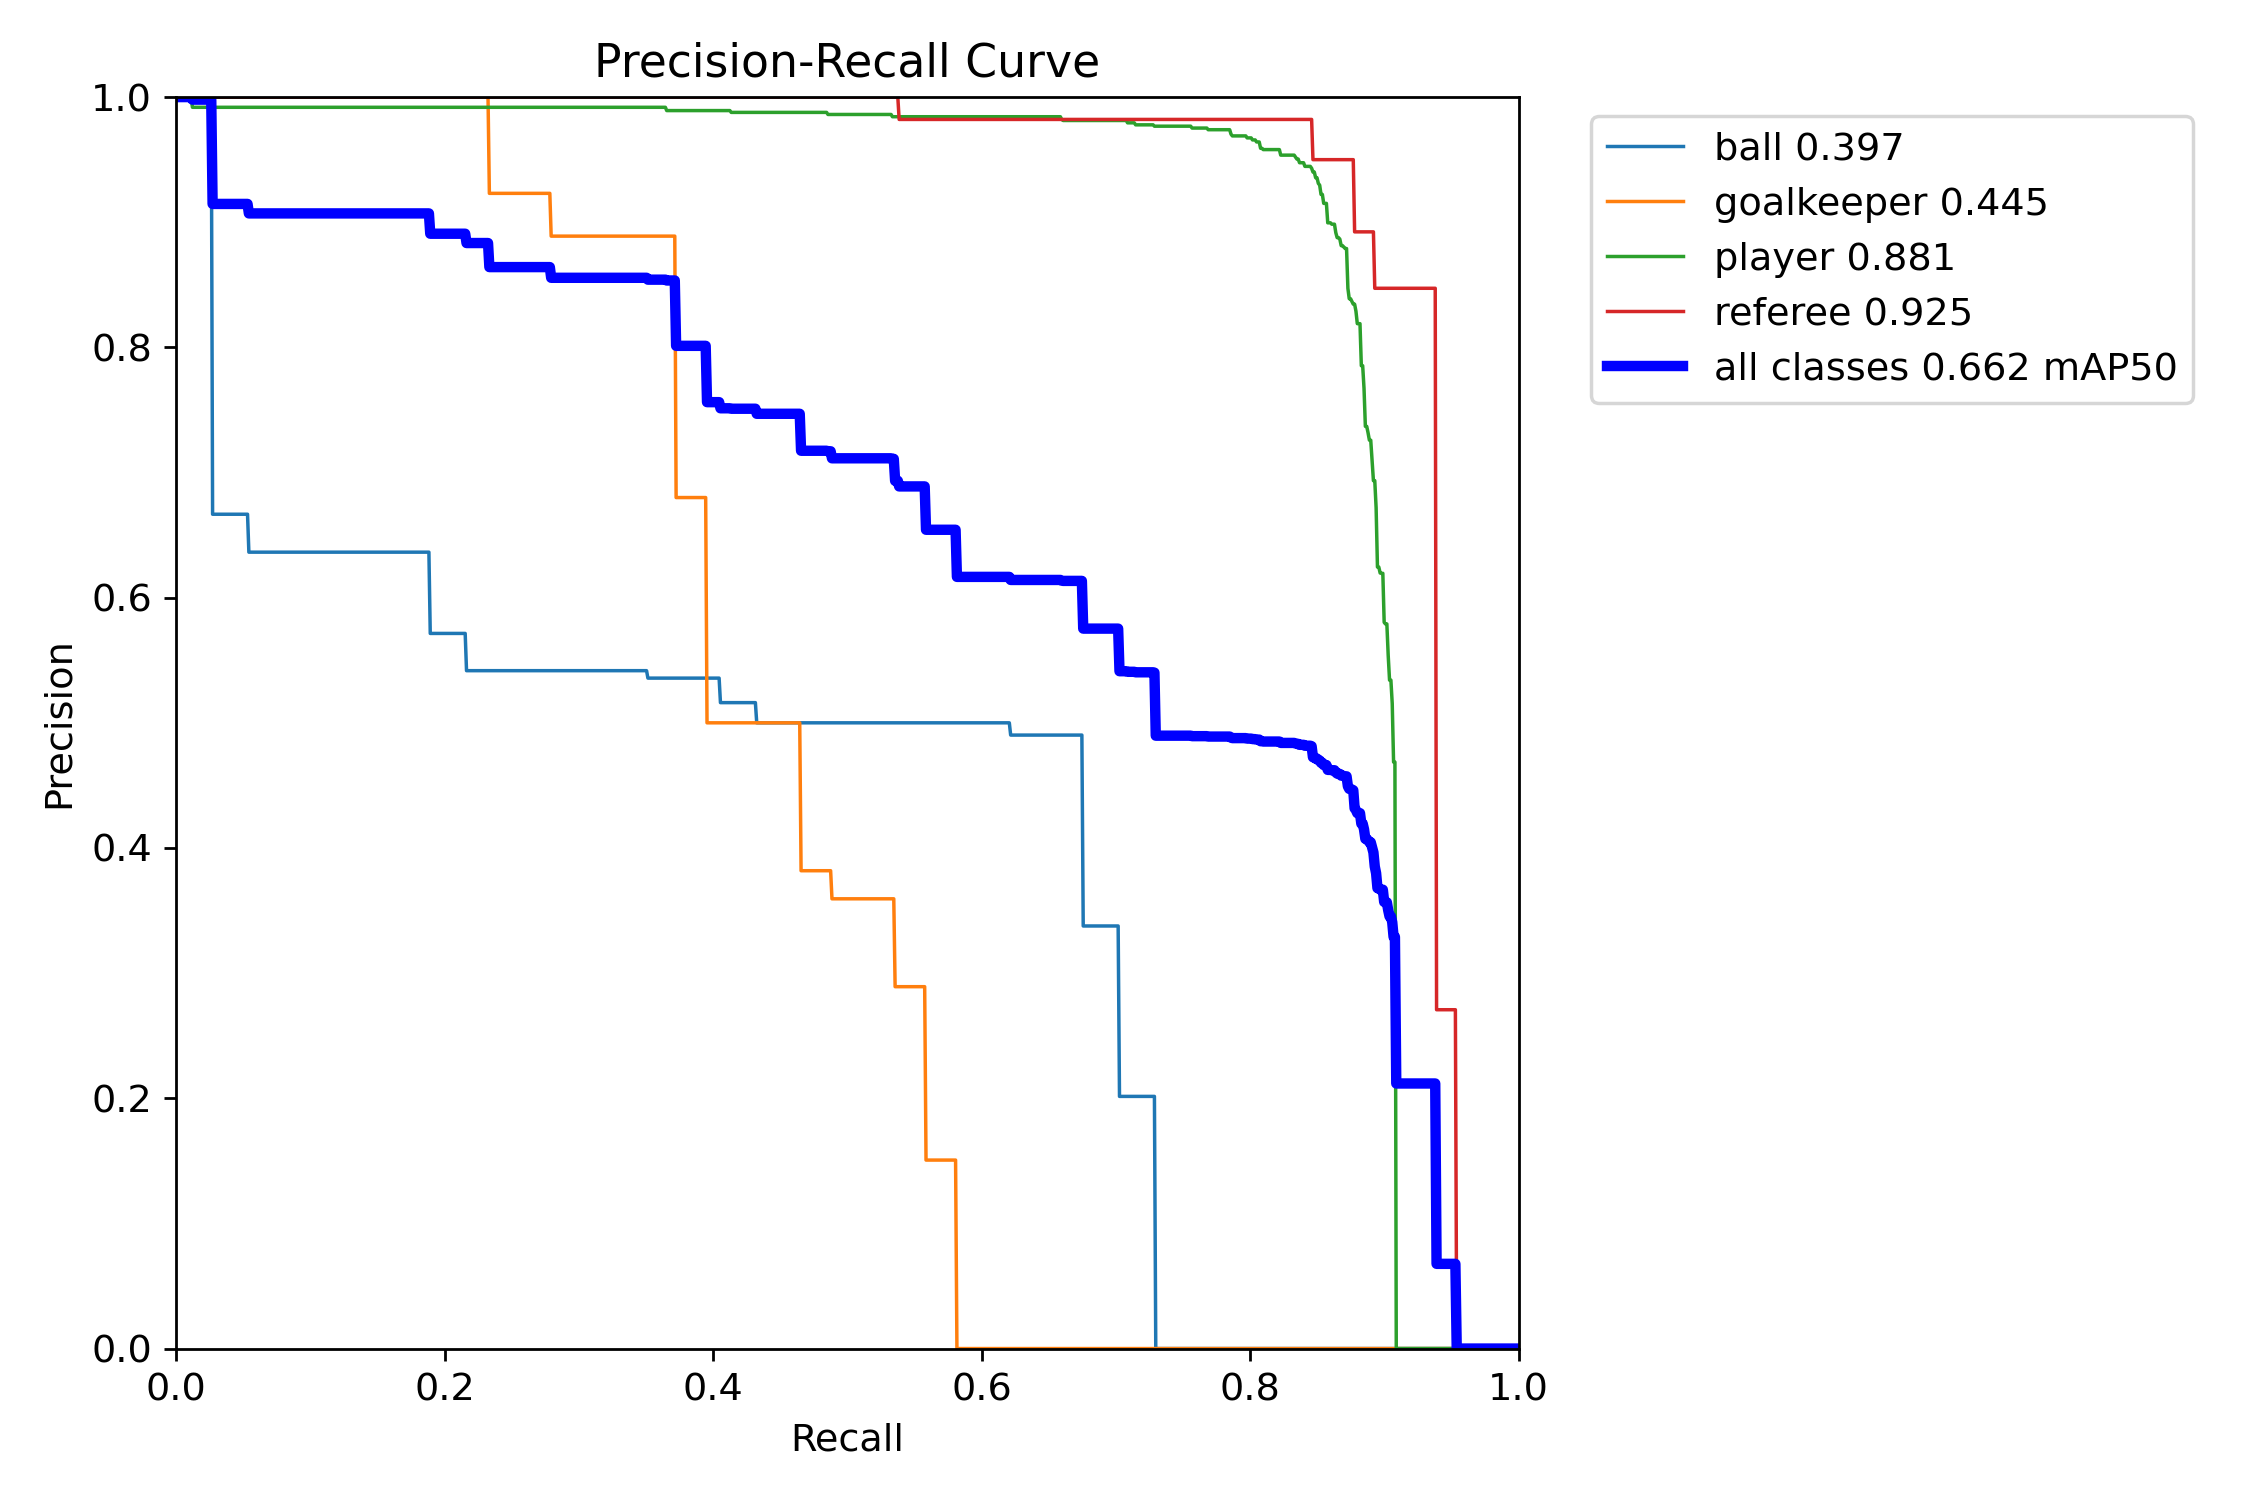

In [ ]:
best_26m = "/content/drive/MyDrive/project_football_WorldCup2026/runs/train_yolo26m/yolo26m_1280/weights/best.pt"

!yolo detect val \
    model="{best_26m}" \
    data="/content/kor_cze_val_yolo/data.yaml" \
    imgsz=1280 \
    project="/content/drive/MyDrive/project_football_WorldCup2026/runs/val_kor_cze" \
    name="yolo26m_1280_eval"

from IPython.display import Image, display
display(Image(filename="/content/drive/MyDrive/project_football_WorldCup2026/runs/val_kor_cze/yolo26m_1280_eval/BoxPR_curve.png", width=650))

In [ ]:
import os, glob, shutil, cv2

os.chdir("/content/drive/MyDrive/project_football_WorldCup2026")

# 1. 기존 best.pt 백업 후, 방금 학습한 YOLO26m best.pt로 교체
if os.path.exists("models/best.pt") and not os.path.exists("models/best_yolov5m_backup.pt"):
    shutil.copy2("models/best.pt", "models/best_yolov5m_backup.pt")

candidates = sorted(glob.glob("runs/train_yolo26m/*/weights/best.pt"), key=os.path.getmtime)
assert candidates, "YOLO26m best.pt를 찾지 못했습니다. 학습 폴더 경로를 확인하세요."
new_best = candidates[-1]
shutil.copy2(new_best, "models/best.pt")
print("모델 교체 완료:", new_best, "-> models/best.pt")

# 2. 예전 YOLOv5m 추론 캐시(stub) 삭제 (삭제 안 하면 새 모델이 실행 안 됨!)
old_stub = "stubs/clip_0127_0131_track_stubs.pkl"
if os.path.exists(old_stub):
    os.remove(old_stub)
    print("기존 캐시 삭제 완료:", old_stub)

# 3. trackers/tracker.py의 predict()에 imgsz=1280 반영 (1회만 적용)
with open("trackers/tracker.py", "r") as f:
    code = f.read()

if "imgsz=1280" not in code:
    code = code.replace("conf=0.1)", "conf=0.1, imgsz=1280)")
    with open("trackers/tracker.py", "w") as f:
        f.write(code)
    print("trackers/tracker.py에 imgsz=1280 적용 완료")

# 4. main.py 실행 (clip_0127_0131.mp4 분석)
!python -u main.py

모델 교체 완료: runs/train_yolo26m/yolo26m_1280/weights/best.pt -> models/best.pt
기존 캐시 삭제 완료: stubs/clip_0127_0131_track_stubs.pkl
trackers/tracker.py에 imgsz=1280 적용 완료
/content/drive/MyDrive/project_football_WorldCup2026/trackers/tracker.py:15: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack()

0: 736x1280 2 players, 48.4ms
1: 736x1280 2 players, 48.4ms
2: 736x1280 2 players, 48.4ms
3: 736x1280 2 players, 48.4ms
4: 736x1280 2 players, 48.4ms
5: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
6: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
7: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
8: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
9: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
10: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
11: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
12: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
13: 736x1280 1 ball, 18 players, 2 referees, 48.4ms
14: 736x1280 1 ball, 

In [ ]:
with open("main.py", "r") as f:
    code = f.read()

old_line = "team_assigner.assign_team_color(video_frames[0], tracks['players'][0])"
new_lines = """init_frame = max(range(len(tracks['players'])), key=lambda i: len(tracks['players'][i]))
    team_assigner.assign_team_color(video_frames[init_frame], tracks['players'][init_frame])"""

assert old_line in code, "main.py에서 해당 줄을 찾지 못했습니다."
code = code.replace(old_line, new_lines)
with open("main.py", "w") as f:
    f.write(code)

print("main.py 수정 완료! 재실행합니다.")
!python -u main.py

main.py 수정 완료! 재실행합니다.
/content/drive/MyDrive/project_football_WorldCup2026/trackers/tracker.py:15: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack()
frame count check: 240 240 240


In [ ]:
import json, os, shutil, torch, pandas as pd
from ultralytics import YOLO

# 0. /content/kor_cze_val_yolo 재생성 (세션 초기화 복구)
coco_valid_dir = "/content/drive/MyDrive/project_football_WorldCup2026/input_videos/2026worldcup kor vs cze-Uploaded on 11-22-26 at 8-57 pm - Auto Label.coco/valid"
out_root = "/content/kor_cze_val_yolo"
data_yaml = os.path.join(out_root, "data.yaml")

if not os.path.exists(data_yaml):
    img_out = os.path.join(out_root, "images/val")
    lbl_out = os.path.join(out_root, "labels/val")
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    with open(os.path.join(coco_valid_dir, "_annotations.coco.json"), "r") as f:
        coco = json.load(f)

    cat_map = {1: 0, 2: 1, 3: 2, 4: 3}
    img_info = {im["id"]: im for im in coco["images"]}
    anns_by_img = {im["id"]: [] for im in coco["images"]}
    for ann in coco["annotations"]:
        if ann["category_id"] in cat_map:
            anns_by_img[ann["image_id"]].append(ann)

    for img_id, info in img_info.items():
        fname = info["file_name"]
        src_img = os.path.join(coco_valid_dir, fname)
        if not os.path.exists(src_img):
            continue
        shutil.copy2(src_img, os.path.join(img_out, fname))
        w, h = info["width"], info["height"]
        stem = os.path.splitext(fname)[0]
        lines = [
            f"{cat_map[a['category_id']]} {(a['bbox'][0]+a['bbox'][2]/2)/w:.6f} {(a['bbox'][1]+a['bbox'][3]/2)/h:.6f} {a['bbox'][2]/w:.6f} {a['bbox'][3]/h:.6f}"
            for a in anns_by_img[img_id]
        ]
        with open(os.path.join(lbl_out, f"{stem}.txt"), "w") as lf:
            lf.write("\n".join(lines))

    with open(data_yaml, "w") as yf:
        yf.write(f"path: {out_root}\ntrain: images/val\nval: images/val\nnames:\n  0: ball\n  1: goalkeeper\n  2: player\n  3: referee\n")
    print("검증셋 재생성 완료!")

# 1. 2x2 통제 실험 실행
models = {
    "YOLOv5m": "/content/drive/MyDrive/project_football_WorldCup2026/models/best_yolov5m_backup.pt",
    "YOLO26m": "/content/drive/MyDrive/project_football_WorldCup2026/models/best.pt",
}

rows = []
for name, mpath in models.items():
    for imgsz in [640, 1280]:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        model = YOLO(mpath)
        res = model.val(data=data_yaml, imgsz=imgsz, plots=False, verbose=False)

        inf_ms = res.speed["inference"]
        vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

        rows.append({
            "Model": name,
            "ImgSz": imgsz,
            "All mAP@50": round(float(res.box.map50), 3),
            "All mAP@50-95": round(float(res.box.map), 3),
            "Ball AP@50": round(float(res.box.ap50[0]), 3),
            "Player AP@50": round(float(res.box.ap50[2]), 3),
            "Inf (ms)": round(inf_ms, 1),
            "FPS": round(1000.0 / inf_ms, 1),
            "Peak VRAM (MB)": round(vram_mb, 1),
        })

df_ablation = pd.DataFrame(rows)
print(df_ablation.to_string(index=False))

검증셋 재생성 완료!
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5m summary (fused): 107 layers, 25,047,532 parameters, 0 gradients, 64.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3112.9±866.8 MB/s, size: 351.3 KB)
val: Scanning /content/kor_cze_val_yolo/labels/val... 55 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 754.4it/s 0.1s
val: New cache created: /content/kor_cze_val_yolo/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.1it/s 1.9s
                   all         55        811        0.7      0.541      0.552       0.39
Speed: 0.9ms preprocess, 12.7ms inference, 0.0ms loss, 2.7ms postprocess per image
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5m summary (fused): 107 layers, 25,047,532 parameters, 0 gradients, 64.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3106.1±839.8 MB/s, si

In [ ]:
import os, cv2, numpy as np
from utils import save_video
from trackers import Tracker
from team_assigner import TeamAssigner
from player_ball_assigner import PlayerBallAssigner
from camera_movement_estimator import CameraMovementEstimator

os.chdir("/content/drive/MyDrive/project_football_WorldCup2026")
video_path = "input_videos/Highlights _ Korea Republic 2-1 Czechia _ FIFA World Cup 2026™.mp4"
start_sec, end_sec = 0, 35

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
s_f, e_f = int(start_sec * fps), int(end_sec * fps)
cap.set(cv2.CAP_PROP_POS_FRAMES, s_f)

video_frames = []
for _ in range(e_f - s_f):
    ret, frame = cap.read()
    if not ret:
        break
    # Colab RAM 초과 방지 (YOLO imgsz=1280과 동일한 가로 1280으로 맞춤)
    video_frames.append(cv2.resize(frame, (1280, 720)))
cap.release()
print(f"로드 완료: {len(video_frames)} 프레임 (FPS: {fps:.2f})")

tag = "kor_cze_0_35s"
tracker = Tracker("models/best.pt")
tracks = tracker.get_object_tracks(video_frames, read_from_stub=False, stub_path=f"stubs/{tag}_track.pkl")

tracks["ball"] = tracker.interpolate_ball_position(tracks["ball"])

team_assigner = TeamAssigner()
init_f = max(range(len(tracks["players"])), key=lambda i: len(tracks["players"][i]))
team_assigner.assign_team_color(video_frames[init_f], tracks["players"][init_f])

for f_idx, p_track in enumerate(tracks["players"]):
    for pid, tr in p_track.items():
        t = team_assigner.get_player_team(video_frames[f_idx], tr["bbox"], pid)
        tracks["players"][f_idx][pid]["team"] = t
        tracks["players"][f_idx][pid]["team_color"] = team_assigner.team_colors[t]

player_assigner = PlayerBallAssigner()
team_ball_control = []
for f_idx, p_track in enumerate(tracks["players"]):
    ball_bbox = tracks["ball"][f_idx][1]["bbox"]
    pid = player_assigner.assign_ball_to_player(p_track, ball_bbox)
    if pid != -1:
        tracks["players"][f_idx][pid]["has_ball"] = True
        team_ball_control.append(tracks["players"][f_idx][pid]["team"])
    else:
        team_ball_control.append(team_ball_control[-1] if team_ball_control else 0)

team_ball_control = np.array(team_ball_control)
np.save(f"stubs/{tag}_ball_control.npy", team_ball_control)
print(f"점유율 추론 완료! 총 {len(team_ball_control)}프레임 저장됨")

로드 완료: 2097 프레임 (FPS: 59.94)


/content/drive/MyDrive/project_football_WorldCup2026/trackers/tracker.py:15: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack()



0: 736x1280 21 players, 4 referees, 59.7ms
1: 736x1280 21 players, 4 referees, 59.7ms
2: 736x1280 21 players, 4 referees, 59.7ms
3: 736x1280 21 players, 4 referees, 59.7ms
4: 736x1280 21 players, 4 referees, 59.7ms
5: 736x1280 21 players, 4 referees, 59.7ms
6: 736x1280 21 players, 4 referees, 59.7ms
7: 736x1280 21 players, 5 referees, 59.7ms
8: 736x1280 21 players, 5 referees, 59.7ms
9: 736x1280 21 players, 5 referees, 59.7ms
10: 736x1280 21 players, 5 referees, 59.7ms
11: 736x1280 21 players, 5 referees, 59.7ms
12: 736x1280 21 players, 5 referees, 59.7ms
13: 736x1280 21 players, 6 referees, 59.7ms
14: 736x1280 21 players, 6 referees, 59.7ms
15: 736x1280 21 players, 6 referees, 59.7ms
16: 736x1280 21 players, 7 referees, 59.7ms
17: 736x1280 21 players, 7 referees, 59.7ms
18: 736x1280 21 players, 7 referees, 59.7ms
19: 736x1280 1 ball, 21 players, 7 referees, 59.7ms
Speed: 4.9ms preprocess, 59.7ms inference, 1.1ms postprocess per image at shape (1, 3, 736, 1280)

0: 736x1280 21 players

In [ ]:
import numpy as np
from collections import Counter

# 1. 0~9초 구간에서 공-선수 최소 거리 확인
s0, e0 = 0, int(9.0 * fps)
min_dists = []
for f_idx in range(s0, e0):
    bx1, by1, bx2, by2 = tracks["ball"][f_idx][1]["bbox"]
    bcx, bcy = (bx1 + bx2) / 2, (by1 + by2) / 2
    d_min = 9999
    for pid, tr in tracks["players"][f_idx].items():
        px1, py1, px2, py2 = tr["bbox"]
        d = min(np.hypot(px1 - bcx, py2 - bcy), np.hypot(px2 - bcx, py2 - bcy))
        if d < d_min:
            d_min = d
    min_dists.append(d_min)

print(f"[0~9초 진단] 공-선수 최소거리 중앙값: {np.median(min_dists):.1f}px | 최솟값: {np.min(min_dists):.1f}px | 70px 이하 프레임: {sum(d <= 70 for d in min_dists)}/{len(min_dists)}")

# 2. 개선 로직 비교: 거리 기준(고정 70px vs 선수 키 비례) + 히스테리시스(N프레임 연속 유지 시 전환)
def run_possession(dist_mode="fixed_70", hold_frames=1):
    ctrl = []
    current_team = 0
    cand_team, cand_cnt = 0, 0

    for f_idx, p_track in enumerate(tracks["players"]):
        bx1, by1, bx2, by2 = tracks["ball"][f_idx][1]["bbox"]
        bcx, bcy = (bx1 + bx2) / 2, (by1 + by2) / 2

        best_team, best_score = 0, 9999
        for pid, tr in p_track.items():
            px1, py1, px2, py2 = tr["bbox"]
            p_h = max(py2 - py1, 1.0)
            d = min(np.hypot(px1 - bcx, py2 - bcy), np.hypot(px2 - bcx, py2 - bcy))
            thresh = 70.0 if dist_mode == "fixed_70" else (120.0 if dist_mode == "fixed_120" else p_h * 1.5)
            if d < thresh and d < best_score:
                best_score = d
                best_team = tr["team"]

        if best_team != 0:
            if current_team == 0:
                current_team = best_team
            elif best_team == current_team:
                cand_team, cand_cnt = 0, 0
            else:
                if best_team == cand_team:
                    cand_cnt += 1
                else:
                    cand_team, cand_cnt = best_team, 1
                if cand_cnt >= hold_frames:
                    current_team = best_team
                    cand_team, cand_cnt = 0, 0
        ctrl.append(current_team)
    return np.array(ctrl)

def eval_ctrl(ctrl, label):
    valid = gt_frames > 0
    pv, gv = ctrl[valid], gt_frames[valid]
    a1 = np.mean(pv == gv)
    a2 = np.mean((3 - np.where(pv > 0, pv, 3)) == gv)  # 0은 오답 유지
    if a2 > a1:
        aligned = np.where(ctrl > 0, 3 - ctrl, 0)
        acc = a2
    else:
        aligned = ctrl
        acc = a1
    gt_k = np.mean(gv == 1) * 100
    pr_k = np.mean(aligned[valid] == 1) * 100
    u0 = np.mean(aligned[valid] == 0) * 100
    print(f"{label:32s} | 정확도: {acc*100:5.1f}% | KOR 예측: {pr_k:5.1f}% (정답 {gt_k:4.1f}%, 오차 {abs(gt_k-pr_k):4.1f}%p) | 미배정: {u0:4.1f}%")

print("\n[점유율 로직 개선 실험 결과]")
eval_ctrl(run_possession("fixed_70",  hold_frames=1),  "Baseline (70px, 즉시 전환)")
eval_ctrl(run_possession("fixed_120", hold_frames=1),  "거리 완화 (120px, 즉시 전환)")
eval_ctrl(run_possession("height_1.5", hold_frames=1), "키 비례 (1.5×H, 즉시 전환)")
eval_ctrl(run_possession("height_1.5", hold_frames=15),"키 비례 (1.5×H) + 0.25s 유지")
eval_ctrl(run_possession("height_1.5", hold_frames=30),"키 비례 (1.5×H) + 0.50s 유지")

[0~9초 진단] 공-선수 최소거리 중앙값: 234.2px | 최솟값: 113.0px | 70px 이하 프레임: 0/539

[점유율 로직 개선 실험 결과]
Baseline (70px, 즉시 전환)           | 정확도:  37.6% | KOR 예측:  37.1% (정답 58.3%, 오차 21.3%p) | 미배정: 37.5%
거리 완화 (120px, 즉시 전환)             | 정확도:  37.3% | KOR 예측:  37.6% (정답 58.3%, 오차 20.7%p) | 미배정: 36.6%
키 비례 (1.5×H, 즉시 전환)              | 정확도:  37.6% | KOR 예측:  37.0% (정답 58.3%, 오차 21.3%p) | 미배정: 37.5%
키 비례 (1.5×H) + 0.25s 유지          | 정확도:  32.3% | KOR 예측:  28.2% (정답 58.3%, 오차 30.2%p) | 미배정: 37.5%
키 비례 (1.5×H) + 0.50s 유지          | 정확도:  32.9% | KOR 예측:  37.1% (정답 58.3%, 오차 21.3%p) | 미배정: 37.5%


/content/drive/MyDrive/project_football_WorldCup2026/trackers/tracker.py:15: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack()



0: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
1: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
2: 736x1280 1 ball, 1 goalkeeper, 20 players, 3 referees, 52.8ms
3: 736x1280 1 ball, 1 goalkeeper, 20 players, 3 referees, 52.8ms
4: 736x1280 1 ball, 1 goalkeeper, 20 players, 3 referees, 52.8ms
5: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
6: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
7: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
8: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
9: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
10: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
11: 736x1280 2 balls, 1 goalkeeper, 19 players, 3 referees, 52.8ms
12: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
13: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
14: 736x1280 1 ball, 1 goalkeeper, 19 players, 3 referees, 52.8ms
15: 736x1280 2 bal

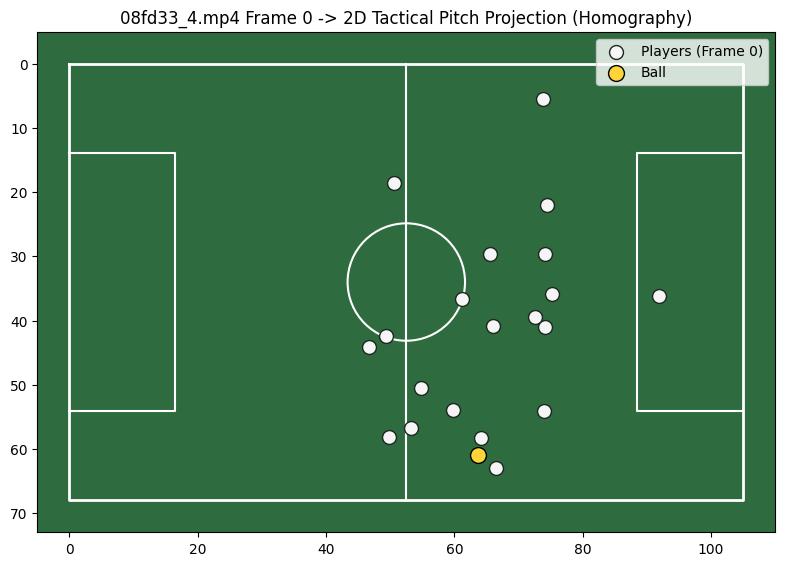

In [ ]:
import os, cv2
import numpy as np
import matplotlib.pyplot as plt
from utils import read_video
from trackers import Tracker
from camera_movement_estimator import CameraMovementEstimator

os.chdir("/content/drive/MyDrive/project_football_WorldCup2026")

# 1. 08fd33_4.mp4 기준 6개 FIFA 공식 교차점으로 Homography 행렬 계산
src_pts = np.array([
    [425, 272],   # 하프라인 상단
    [527, 998],   # 하프라인 하단
    [442, 405],   # 센터 서클 상단
    [472, 570],   # 센터 서클 하단
    [805, 470],   # 센터 서클 우측 끝
    [1415, 298],  # 우측 페널티 박스 좌상단
], dtype=np.float32)

dst_pts = np.array([
    [52.5,  0.00],
    [52.5,  68.00],
    [52.5,  24.85],
    [52.5,  43.15],
    [61.65, 34.00],
    [88.5,  13.84],
], dtype=np.float32)

H_mat, _ = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC)

# 2. 영상 로드 & YOLO26m 추적 + Optical Flow 카메라 이동량 추출 (캐시 자동 저장)
video_frames = read_video("input_videos/08fd33_4.mp4")
tracker = Tracker("models/best.pt")
tracks = tracker.get_object_tracks(
    video_frames,
    read_from_stub=True,
    stub_path="stubs/08fd33_4_yolo26m_track_stub.pkl"
)
tracks["ball"] = tracker.interpolate_ball_position(tracks["ball"])

cam_est = CameraMovementEstimator(video_frames[0])
cam_mov = cam_est.get_camera_movement(
    video_frames,
    read_from_stub=True,
    stub_path="stubs/08fd33_4_cam_stub.pkl"
)

def to_meters(x, y, dx, dy):
    pt = np.array([[[x - dx, y - dy]]], dtype=np.float32)
    m = cv2.perspectiveTransform(pt, H_mat)[0][0]
    return float(m[0]), float(m[1])

# 3. 픽셀(70px) vs Homography 실거리(2.5m) 점유 판정 비교
cum_dx, cum_dy = 0.0, 0.0
px_hits, m_hits, both_same = 0, 0, 0
sample_f0 = None

for f_idx in range(len(tracks["players"])):
    cum_dx += cam_mov[f_idx][0]
    cum_dy += cam_mov[f_idx][1]

    bx1, by1, bx2, by2 = tracks["ball"][f_idx][1]["bbox"]
    bcx, bcy = (bx1 + bx2) / 2, (by1 + by2) / 2
    bmx, bmy = to_meters(bcx, bcy, cum_dx, cum_dy)

    best_px_id, best_px_d = -1, 70.0
    best_m_id, best_m_d = -1, 2.5  # 실제 거리 2.5m

    players_m = []
    for pid, tr in tracks["players"][f_idx].items():
        px1, py1, px2, py2 = tr["bbox"]
        d_px = min(np.hypot(px1 - bcx, py2 - bcy), np.hypot(px2 - bcx, py2 - bcy))
        if d_px < best_px_d:
            best_px_d, best_px_id = d_px, pid

        pmx, pmy = to_meters((px1 + px2) / 2, py2, cum_dx, cum_dy)
        players_m.append((pmx, pmy))
        d_m = np.hypot(pmx - bmx, pmy - bmy)
        if d_m < best_m_d:
            best_m_d, best_m_id = d_m, pid

    if best_px_id != -1: px_hits += 1
    if best_m_id  != -1: m_hits  += 1
    if best_px_id == best_m_id: both_same += 1

    if f_idx == 0:
        sample_f0 = (players_m, (bmx, bmy))

N = len(tracks["players"])
print(f"=== 08fd33_4.mp4: Homography(2.5m) vs 픽셀(70px) 비교 (총 {N}프레임) ===")
print(f" - 70px 기준 점유 판정률 : {px_hits}/{N} ({px_hits/N*100:.1f}%)")
print(f" - 2.5m 기준 점유 판정률 : {m_hits}/{N} ({m_hits/N*100:.1f}%)")
print(f" - 두 방식 판정 일치율   : {both_same}/{N} ({both_same/N*100:.1f}%)")

# 4. Frame 0 2D 탑뷰 미니맵 시각화 (정합도 바로 확인!)
players_m, (bmx, bmy) = sample_f0
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.set_facecolor("#2E6B3E")
ax.plot([0, 105, 105, 0, 0], [0, 0, 68, 68, 0], "w-", lw=2)
ax.plot([52.5, 52.5], [0, 68], "w-", lw=1.5)
circle = plt.Circle((52.5, 34.0), 9.15, color="white", fill=False, lw=1.5)
ax.add_patch(circle)
ax.plot([0, 16.5, 16.5, 0], [13.84, 13.84, 54.16, 54.16], "w-", lw=1.5)
ax.plot([105, 88.5, 88.5, 105], [13.84, 13.84, 54.16, 54.16], "w-", lw=1.5)

xs, ys = zip(*players_m)
ax.scatter(xs, ys, c="#F5F5F5", edgecolors="#1E2621", s=100, label="Players (Frame 0)", zorder=4)
ax.scatter([bmx], [bmy], c="#FFD43B", edgecolors="black", s=130, label="Ball", zorder=5)
ax.set_xlim(-5, 110); ax.set_ylim(73, -5)
ax.set_aspect("equal")
ax.set_title("08fd33_4.mp4 Frame 0 -> 2D Tactical Pitch Projection (Homography)")
ax.legend(loc="upper right")
plt.show()

In [ ]:
!pip install -q inference-sdk git+https://github.com/roboflow/sports.git

import cv2, numpy as np
import matplotlib.pyplot as plt
from inference_sdk import InferenceHTTPClient
from sports.configs.soccer import SoccerPitchConfiguration
from sports.common.view import ViewTransformer
from sports.annotators.soccer import draw_pitch, draw_points_on_pitch

# 1. Roboflow 키포인트 모델 클라이언트 연결 (노트북 8번 셀의 본인 API Key 입력)
CLIENT = InferenceHTTPClient(
    api_url="https://detect.roboflow.com",
    api_key="zUjuyJm25IqTd29mZ8CE"
)
CONFIG = SoccerPitchConfiguration()

# 2. 한국 vs 체코 영상(clip_0127_0131.mp4) 샘플 프레임 1장 테스트
base = "/content/drive/MyDrive/project_football_WorldCup2026"
cap = cv2.VideoCapture(f"{base}/input_videos/clip_0127_0131.mp4")
ret, frame = cap.read()
cap.release()

# 3. 32개 경기장 키포인트 자동 추론
result = CLIENT.infer(frame, model_id="football-field-detection-f07vi/14")

src_pts, dst_pts = [], []
for pred in result.get("predictions", []):
    for kp in pred.get("keypoints", []):
        if kp["confidence"] >= 0.5:
            cid = int(kp["class_id"])
            src_pts.append([kp["x"], kp["y"]])
            dst_pts.append(CONFIG.vertices[cid])

print(f"자동 탐지된 고신뢰도 경기장 키포인트 수: {len(src_pts)}개 (최소 4개 필요)")

if len(src_pts) >= 4:
    transformer = ViewTransformer(
        source=np.array(src_pts, dtype=np.float32),
        target=np.array(dst_pts, dtype=np.float32)
    )

    # 기존 YOLO26m stub에서 Frame 0 선수·공 좌표 불러와 2D 피치에 투영
    import pickle
    with open(f"{base}/stubs/clip_0127_0131_track_stubs.pkl", "rb") as f:
        tracks = pickle.load(f)

    p_xy = np.array([[(tr["bbox"][0]+tr["bbox"][2])/2, tr["bbox"][3]] for tr in tracks["players"][0].values()], dtype=np.float32)
    p_pitch = transformer.transform_points(points=p_xy)

    # 2D 탑뷰 피치 그리기
    pitch_img = draw_pitch(CONFIG)
    pitch_img = draw_points_on_pitch(CONFIG, xy=p_pitch, face_color=(255, 255, 255), edge_color=(30, 38, 33), radius=14, pitch=pitch_img)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    # 왼쪽: 원본 프레임 + 탐지된 키포인트(노란 점)
    vis = frame.copy()
    for x, y in src_pts:
        cv2.circle(vis, (int(x), int(y)), 7, (0, 255, 255), -1)
    axes[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Auto-Detected Field Keypoints ({len(src_pts)} pts)")
    axes[0].axis("off")

    # 오른쪽: 동적 Homography 2D 탑뷰 미니맵
    axes[1].imshow(cv2.cvtColor(pitch_img, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Dynamic Homography -> 2D Tactical Pitch")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
자동 탐지된 고신뢰도 경기장 키포인트 수: 0개 (최소 4개 필요)


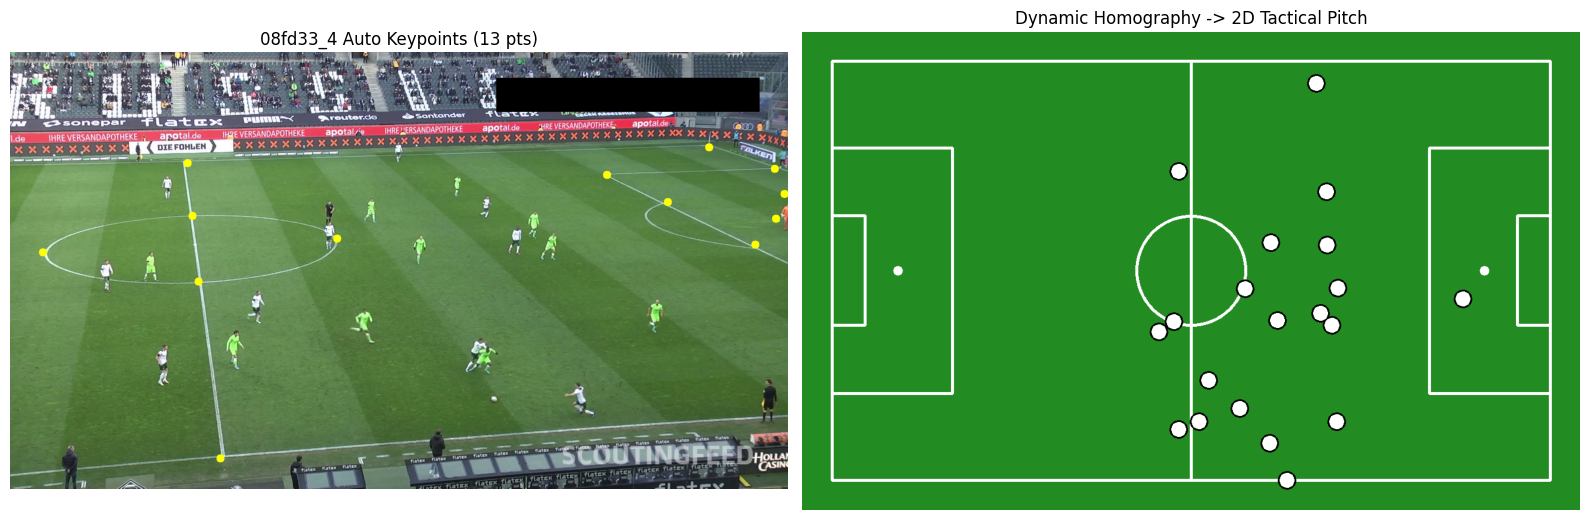

In [ ]:
import supervision as sv

pitch_img = draw_pitch(CONFIG)
pitch_img = draw_points_on_pitch(
    CONFIG,
    xy=p_pitch,
    face_color=sv.Color.WHITE,
    edge_color=sv.Color.BLACK,
    radius=14,
    pitch=pitch_img
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
vis = f2.copy()
for x, y in src_pts:
    cv2.circle(vis, (int(x), int(y)), 10, (0, 255, 255), -1)
axes[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"08fd33_4 Auto Keypoints ({len(src_pts)} pts)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(pitch_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Dynamic Homography -> 2D Tactical Pitch")
axes[1].axis("off")
plt.tight_layout()
plt.show()

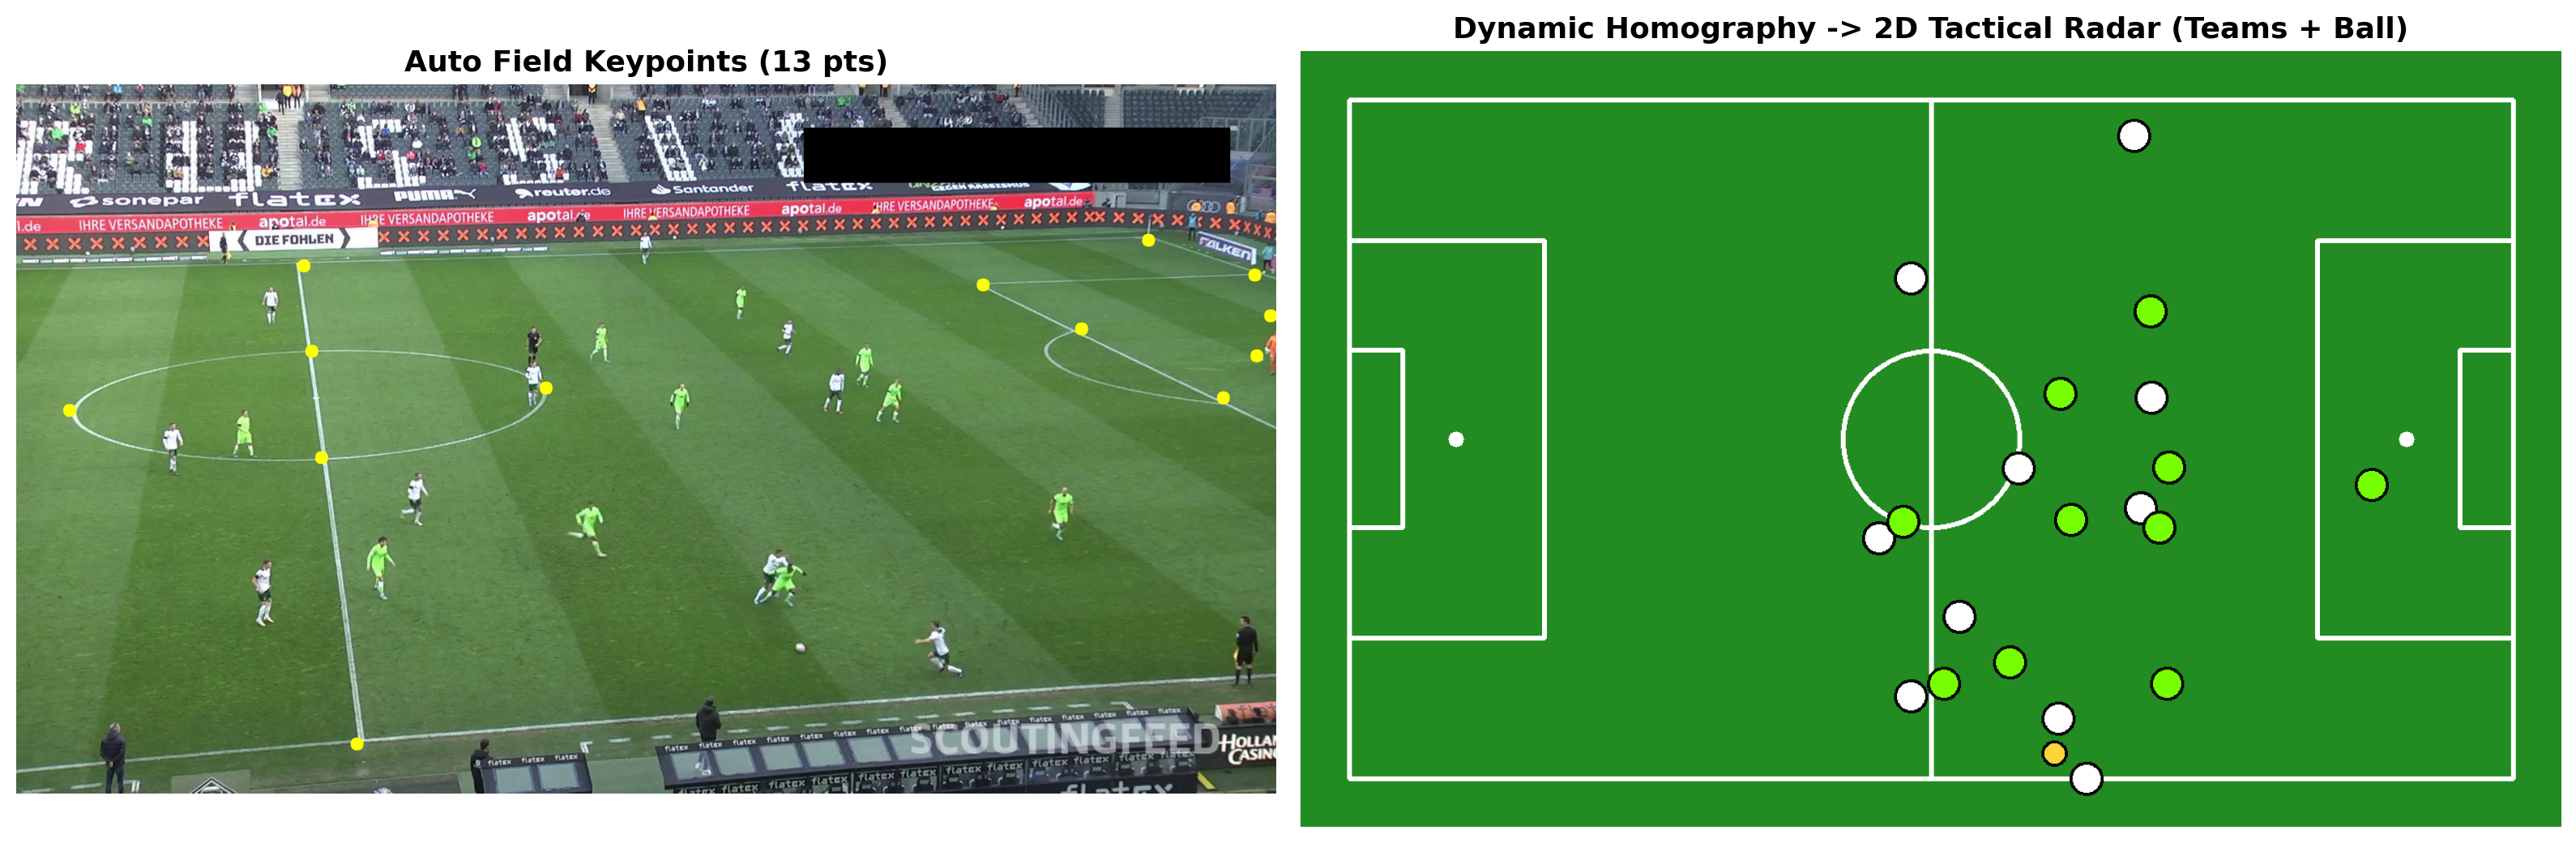

포트폴리오용 이미지 저장 완료: /content/drive/MyDrive/project_football_WorldCup2026/output_videos/homography_tactical_view.png
KOR vs CZE frame   0 -> predictions: 1, keypoints(>=0.3): 12
KOR vs CZE frame  60 -> predictions: 1, keypoints(>=0.3): 9
KOR vs CZE frame 120 -> predictions: 1, keypoints(>=0.3): 10
KOR vs CZE frame 180 -> predictions: 1, keypoints(>=0.3): 10


In [ ]:
import cv2, pickle, numpy as np
import matplotlib.pyplot as plt
import supervision as sv
from team_assigner import TeamAssigner
from trackers import Tracker

# 1. 08fd33_4 Frame 0에 팀 색상 + 공 위치까지 입힌 2D 전술 피치 저장
tracker_tmp = Tracker(f"{base}/models/best.pt")
tr2["ball"] = tracker_tmp.interpolate_ball_position(tr2["ball"])

ta = TeamAssigner()
ta.assign_team_color(f2, tr2["players"][0])

t1_pts, t2_pts = [], []
for pid, info in tr2["players"][0].items():
    t = ta.get_player_team(f2, info["bbox"], pid)
    pt = [(info["bbox"][0] + info["bbox"][2]) / 2, info["bbox"][3]]
    (t1_pts if t == 1 else t2_pts).append(pt)

bx1, by1, bx2, by2 = tr2["ball"][0][1]["bbox"]
ball_pt = np.array([[(bx1 + bx2) / 2, by2]], dtype=np.float32)

pitch_img = draw_pitch(CONFIG)
if t1_pts:
    pitch_img = draw_points_on_pitch(CONFIG, xy=vt.transform_points(np.array(t1_pts, np.float32)),
                                     face_color=sv.Color.from_hex("#FFFFFF"), edge_color=sv.Color.BLACK, radius=16, pitch=pitch_img)
if t2_pts:
    pitch_img = draw_points_on_pitch(CONFIG, xy=vt.transform_points(np.array(t2_pts, np.float32)),
                                     face_color=sv.Color.from_hex("#76FF03"), edge_color=sv.Color.BLACK, radius=16, pitch=pitch_img)
pitch_img = draw_points_on_pitch(CONFIG, xy=vt.transform_points(ball_pt),
                                 face_color=sv.Color.from_hex("#FFD43B"), edge_color=sv.Color.BLACK, radius=12, pitch=pitch_img)

out_vis = f"{base}/output_videos/homography_tactical_view.png"
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=200)
vis = f2.copy()
for x, y in src_pts:
    cv2.circle(vis, (int(x), int(y)), 10, (0, 255, 255), -1)
axes[0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Auto Field Keypoints ({len(src_pts)} pts)", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(pitch_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Dynamic Homography -> 2D Tactical Radar (Teams + Ball)", fontsize=13, fontweight="bold")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(out_vis, dpi=200, bbox_inches="tight")
plt.show()
print("포트폴리오용 이미지 저장 완료:", out_vis)

# 2. 한국 vs 체코(clip_0127_0131.mp4) 여러 프레임에서 키포인트 탐지 여부 체크
from inference_sdk import InferenceConfiguration
CLIENT.configure(InferenceConfiguration(confidence_threshold=0.05))
cap_k = cv2.VideoCapture(f"{base}/input_videos/clip_0127_0131.mp4")
for fi in [0, 60, 120, 180]:
    cap_k.set(cv2.CAP_PROP_POS_FRAMES, fi)
    ok, fk = cap_k.read()
    if ok:
        cv2.imwrite("/tmp/fk.jpg", cv2.resize(fk, (640, 640)))
        rk = CLIENT.infer("/tmp/fk.jpg", model_id="football-field-detection-f07vi/14")
        n_pred = len(rk.get("predictions", []))
        n_kp = sum(1 for k in rk["predictions"][0].get("keypoints", []) if k["confidence"] >= 0.3) if n_pred else 0
        print(f"KOR vs CZE frame {fi:3d} -> predictions: {n_pred}, keypoints(>=0.3): {n_kp}")
cap_k.release()

In [ ]:
import os, cv2, copy, pickle
import numpy as np
import pandas as pd
from scipy.stats import mode
from trackers import Tracker
from team_assigner import TeamAssigner
from player_ball_assigner import PlayerBallAssigner

os.chdir("/content/drive/MyDrive/project_football_WorldCup2026")

# 1. kor_cze 0~35초 프레임 로드 (1280x720)
video_path = "input_videos/Highlights _ Korea Republic 2-1 Czechia _ FIFA World Cup 2026™.mp4"
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS) or 59.94
video_frames = []
for _ in range(int(35 * fps)):
    ret, frame = cap.read()
    if not ret:
        break
    video_frames.append(cv2.resize(frame, (1280, 720)))
cap.release()
n_frames = len(video_frames)

# 2. Ground Truth 배열 생성
gt_segments = [
    (0.0,  9.0,  2), (9.0,  11.0, 0), (11.0, 13.0, 1), (13.0, 17.0, 0),
    (17.0, 20.0, 1), (20.0, 22.0, 0), (22.0, 26.0, 1), (26.0, 27.0, 0),
    (27.0, 28.0, 2), (28.0, 29.0, 0), (29.0, 32.0, 1), (32.0, 33.0, 0), (33.0, 35.0, 1),
]
gt_frames = np.zeros(n_frames, dtype=int)
for s_sec, e_sec, t in gt_segments:
    gt_frames[max(0, int(s_sec * fps)) : min(n_frames, int(e_sec * fps))] = t

# 3. 저장된 YOLO26m 캐시 & YOLOv5m 캐시 로드 (v5 캐시 없으면 자동 생성)
with open("stubs/kor_cze_0_35s_track.pkl", "rb") as f:
    tracks_26 = pickle.load(f)
tr_26_helper = Tracker("models/best.pt")
tracks_26["ball"] = tr_26_helper.interpolate_ball_position(tracks_26["ball"])

tr_v5 = Tracker("models/best_yolov5m_backup.pt")
def detect_640(frames):
    dets = []
    for i in range(0, len(frames), 20):
        dets += tr_v5.model.predict(frames[i:i+20], conf=0.1, imgsz=640, verbose=False)
    return dets
tr_v5.detect_frames = detect_640

# 기존 잘못된 캐시(750프레임짜리)가 있을 수 있어 길이 체크 후 로드
v5_stub = "stubs/kor_cze_0_35s_v5_640.pkl"
use_v5_stub = False
if os.path.exists(v5_stub):
    with open(v5_stub, "rb") as f:
        tmp = pickle.load(f)
    if len(tmp["players"]) == n_frames:
        tracks_v5 = tmp
        use_v5_stub = True
if not use_v5_stub:
    tracks_v5 = tr_v5.get_object_tracks(video_frames, read_from_stub=False, stub_path=v5_stub)
tracks_v5["ball"] = tr_v5.interpolate_ball_position(tracks_v5["ball"])

# 4. 평가 함수
def eval_pipeline(tracks_obj, frames_obj, use_improved_logic=False):
    tr_ball = tracks_obj["ball"]
    ta = TeamAssigner()
    init_f = max(range(len(tracks_obj["players"])), key=lambda i: len(tracks_obj["players"][i]))
    ta.assign_team_color(frames_obj[init_f], tracks_obj["players"][init_f])
    for fi, pt in enumerate(tracks_obj["players"]):
        for pid, info in pt.items():
            info["team"] = ta.get_player_team(frames_obj[fi], info["bbox"], pid)

    pa = PlayerBallAssigner()
    ctrl = []
    for fi, pt in enumerate(tracks_obj["players"]):
        b_bbox = tr_ball[fi].get(1, {}).get("bbox", [])
        pid = pa.assign_ball_to_player(pt, b_bbox) if len(b_bbox) == 4 else -1
        if pid != -1:
            ctrl.append(pt[pid]["team"])
        else:
            ctrl.append(0 if use_improved_logic else (ctrl[-1] if ctrl else 0))
    ctrl = np.array(ctrl)

    if use_improved_logic:
        win = int(fps * 0.5)
        smoothed = ctrl.copy()
        for i in range(len(ctrl)):
            seg = ctrl[max(0, i - win//2) : min(len(ctrl), i + win//2 + 1)]
            valid_seg = seg[seg > 0]
            if len(valid_seg) > 0:
                smoothed[i] = int(mode(valid_seg, keepdims=False).mode)
        ctrl = smoothed

    valid = gt_frames > 0
    pv, gv = ctrl[valid], gt_frames[valid]
    assigned = pv > 0
    acc1 = np.mean(pv[assigned] == gv[assigned])
    acc2 = np.mean((3 - pv[assigned]) == gv[assigned])
    pv_aligned = np.where(pv > 0, 3 - pv, 0) if acc2 > acc1 else pv

    gt_kor = np.mean(gv == 1) * 100
    # 기존 로직: 전체 유효 프레임 분모 / 개선 로직: 실제 판정(assigned) 프레임 분모
    pred_kor = (np.mean(pv_aligned[assigned] == 1) if use_improved_logic else np.mean(pv_aligned == 1)) * 100

    return {
        "판정구간 정확도(%)": round(np.mean(pv_aligned[assigned] == gv[assigned]) * 100, 1),
        "실제 KOR(%)": round(gt_kor, 1),
        "예측 KOR(%)": round(pred_kor, 1),
        "점유율 오차(%p)": round(abs(gt_kor - pred_kor), 1),
    }

rows = []
for name, tr, imp in [
    ("1. Baseline (YOLOv5m 640 + 기존 로직)", tracks_v5, False),
    ("2. 모델 개선 (YOLO26m 1280 + 기존 로직)", tracks_26, False),
    ("3. 로직 개선 (+ 미배정 제외 · 0.5s 스무딩)", tracks_26, True),
]:
    r = eval_pipeline(copy.deepcopy(tr), video_frames, use_improved_logic=imp)
    r["실험 단계"] = name
    rows.append(r)

df_pos = pd.DataFrame(rows)[["실험 단계", "판정구간 정확도(%)", "실제 KOR(%)", "예측 KOR(%)", "점유율 오차(%p)"]]
print(df_pos.to_string(index=False))

/content/drive/MyDrive/project_football_WorldCup2026/trackers/tracker.py:15: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  self.tracker = sv.ByteTrack()


                            실험 단계  판정구간 정확도(%)  실제 KOR(%)  예측 KOR(%)  점유율 오차(%p)
1. Baseline (YOLOv5m 640 + 기존 로직)         53.3       58.3       34.8        23.5
  2. 모델 개선 (YOLO26m 1280 + 기존 로직)         60.1       58.3       37.0        21.3
   3. 로직 개선 (+ 미배정 제외 · 0.5s 스무딩)         56.3       58.3       51.5         6.8


In [ ]:
import os, cv2, copy, pickle
import numpy as np
import pandas as pd
from scipy.stats import mode
from trackers import Tracker
from team_assigner import TeamAssigner
from player_ball_assigner import PlayerBallAssigner

os.chdir("/content/drive/MyDrive/project_football_WorldCup2026")

# 1. 영상 & 동일 GT 로드 (KOR vs CZE 0~35초)
video_path = "input_videos/Highlights _ Korea Republic 2-1 Czechia _ FIFA World Cup 2026™.mp4"
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS) or 59.94
video_frames = []
for _ in range(int(35 * fps)):
    ret, frame = cap.read()
    if not ret:
        break
    video_frames.append(cv2.resize(frame, (1280, 720)))
cap.release()
n_frames = len(video_frames)

gt_segments = [
    (0.0,  9.0,  2), (9.0,  11.0, 0), (11.0, 13.0, 1), (13.0, 17.0, 0),
    (17.0, 20.0, 1), (20.0, 22.0, 0), (22.0, 26.0, 1), (26.0, 27.0, 0),
    (27.0, 28.0, 2), (28.0, 29.0, 0), (29.0, 32.0, 1), (32.0, 33.0, 0), (33.0, 35.0, 1),
]
gt_frames = np.zeros(n_frames, dtype=int)
for s_sec, e_sec, t in gt_segments:
    gt_frames[max(0, int(s_sec * fps)) : min(n_frames, int(e_sec * fps))] = t

# 2. 저장된 캐시 로드 (YOLOv5m 640 / YOLO26m 1280)
with open("stubs/kor_cze_0_35s_v5_640.pkl", "rb") as f:
    tracks_v5 = pickle.load(f)
with open("stubs/kor_cze_0_35s_track.pkl", "rb") as f:
    tracks_26 = pickle.load(f)

tr_helper = Tracker("models/best.pt")
tracks_v5["ball"] = tr_helper.interpolate_ball_position(tracks_v5["ball"])
tracks_26["ball"] = tr_helper.interpolate_ball_position(tracks_26["ball"])

# 3. 팀 분류 1회 사전 계산 (조건 간 K-Means 랜덤성 제거 = 완벽 통제!)
def assign_teams_once(tracks_obj, frames_obj):
    tr = copy.deepcopy(tracks_obj)
    ta = TeamAssigner()
    init_f = max(range(len(tr["players"])), key=lambda i: len(tr["players"][i]))
    ta.assign_team_color(frames_obj[init_f], tr["players"][init_f])
    for fi, pt in enumerate(tr["players"]):
        for pid, info in pt.items():
            info["team"] = ta.get_player_team(frames_obj[fi], info["bbox"], pid)
    return tr

tr_v5_ready = assign_teams_once(tracks_v5, video_frames)
tr_26_ready = assign_teams_once(tracks_26, video_frames)

# 4. 조건별 분리 평가 함수
def run_condition(tr_ready, exclude_unassigned=False, use_smoothing=False, carry_forward=True):
    pa = PlayerBallAssigner()
    ctrl = []
    for fi, pt in enumerate(tr_ready["players"]):
        b_bbox = tr_ready["ball"][fi].get(1, {}).get("bbox", [])
        pid = pa.assign_ball_to_player(pt, b_bbox) if len(b_bbox) == 4 else -1
        if pid != -1:
            ctrl.append(pt[pid]["team"])
        else:
            ctrl.append((ctrl[-1] if ctrl else 0) if carry_forward else 0)
    ctrl = np.array(ctrl)

    if use_smoothing:
        win = int(fps * 0.5)
        smoothed = ctrl.copy()
        for i in range(len(ctrl)):
            seg = ctrl[max(0, i - win // 2) : min(len(ctrl), i + win // 2 + 1)]
            valid_seg = seg[seg > 0]
            if len(valid_seg) > 0:
                smoothed[i] = int(mode(valid_seg, keepdims=False).mode)
        ctrl = smoothed

    valid = gt_frames > 0
    pv, gv = ctrl[valid], gt_frames[valid]
    assigned = pv > 0

    # 팀 번호 자동 매칭 (판정 구간 기준)
    acc1 = np.mean(pv[assigned] == gv[assigned])
    acc2 = np.mean((3 - pv[assigned]) == gv[assigned])
    pv_aligned = np.where(pv > 0, 3 - pv, 0) if acc2 > acc1 else pv

    correct_cnt = int(np.sum(pv_aligned == gv))
    valid_cnt   = int(valid.sum())
    assign_cnt  = int(assigned.sum())

    overall_acc  = correct_cnt / valid_cnt * 100
    assigned_acc = (correct_cnt / assign_cnt * 100) if assign_cnt > 0 else 0.0
    unassign_pct = (1.0 - assign_cnt / valid_cnt) * 100

    gt_kor = np.mean(gv == 1) * 100
    # 집계 분모: exclude_unassigned=True면 판정된 프레임만, False면 전체 유효 프레임(기존 방식)
    pred_kor = (np.mean(pv_aligned[assigned] == 1) if exclude_unassigned else np.mean(pv_aligned == 1)) * 100

    return {
        "정답/유효": f"{correct_cnt}/{valid_cnt}",
        "판정수": assign_cnt,
        "전체정확도(%)": round(overall_acc, 1),
        "판정정확도(%)": round(assigned_acc, 1),
        "미배정률(%)": round(unassign_pct, 1),
        "예측KOR(%)": round(pred_kor, 1),
        "점유율오차(%p)": round(abs(gt_kor - pred_kor), 1),
    }

conditions = [
    ("1. Baseline (YOLOv5m 640 · 기존)",              tr_v5_ready, False, False, True),
    ("2. 모델 개선 (YOLO26m 1280 · 기존)",            tr_26_ready, False, False, True),
    ("3. [집계 변경] 미배정 분모 제외만 적용",        tr_26_ready, True,  False, True),
    ("4. [예측 변경] 0.5s 스무딩만 적용 (기존 분모)", tr_26_ready, False, True,  True),
    ("5. 미배정 분모 제외 + 0.5s 스무딩 동시 적용",   tr_26_ready, True,  True,  True),
    ("6. carry-forward 제거 + 미배정 제외 + 스무딩",  tr_26_ready, True,  True,  False),
]

rows = []
for label, tr, ex, sm, cf in conditions:
    r = run_condition(tr, exclude_unassigned=ex, use_smoothing=sm, carry_forward=cf)
    r["조건"] = label
    rows.append(r)

cols = ["조건", "전체정확도(%)", "판정정확도(%)", "미배정률(%)", "예측KOR(%)", "점유율오차(%p)", "정답/유효", "판정수"]
df_final = pd.DataFrame(rows)[cols]
print(f"[동일 GT 기준: KOR vs CZE 0~35초 | 유효 {int((gt_frames>0).sum())}프레임 | 실제 KOR {np.mean(gt_frames[gt_frames>0]==1)*100:.1f}%]\n")
print(df_final.to_string(index=False))

[동일 GT 기준: KOR vs CZE 0~35초 | 유효 1438프레임 | 실제 KOR 58.3%]

                                조건  전체정확도(%)  판정정확도(%)  미배정률(%)  예측KOR(%)  점유율오차(%p)    정답/유효  판정수
    1. Baseline (YOLOv5m 640 · 기존)      53.3      53.3      0.0      34.8       23.5 766/1438 1438
      2. 모델 개선 (YOLO26m 1280 · 기존)      37.6      60.1     37.5      37.0       21.3 540/1438  899
          3. [집계 변경] 미배정 분모 제외만 적용      37.6      60.1     37.5      59.2        0.8 540/1438  899
   4. [예측 변경] 0.5s 스무딩만 적용 (기존 분모)      39.2      62.7     37.5      36.6       21.8 564/1438  899
     5. 미배정 분모 제외 + 0.5s 스무딩 동시 적용      39.2      62.7     37.5      58.5        0.2 564/1438  899
6. carry-forward 제거 + 미배정 제외 + 스무딩      30.9      56.3     45.2      51.5        6.8 444/1438  788


In [ ]:
import os, glob, re, shutil

# 1. Google Drive에서 최신 노트북 파일 자동 탐색
matches = glob.glob("/content/drive/MyDrive/**/project_football_WorldCup2026.ipynb", recursive=True)
assert matches, "Drive에서 project_football_WorldCup2026.ipynb를 찾지 못했습니다."
nb_src = sorted(matches, key=os.path.getmtime)[-1]
print("찾은 노트북:", nb_src)

# 2. API Key / 토큰 문자열 마스킹 후 저장소 폴더로 복사
with open(nb_src, "r", encoding="utf-8") as f:
    nb_text = f.read()

nb_text = re.sub(r'api_key\s*=\s*["\'][^"\']+["\']', 'api_key="YOUR_ROBOFLOW_API_KEY"', nb_text)
nb_text = re.sub(r'ghp_[A-Za-z0-9_]+', 'YOUR_GITHUB_TOKEN', nb_text)

repo_dir = "/content/repo_push"
nb_dst = os.path.join(repo_dir, "project_football_WorldCup2026.ipynb")
with open(nb_dst, "w", encoding="utf-8") as f:
    f.write(nb_text)

# 3. 커밋 & 푸시 (아까 인증된 원격 주소 그대로 사용)
os.chdir(repo_dir)
!git add project_football_WorldCup2026.ipynb
!git commit -m "Update Colab notebook with 2x2 ablation, ball tracking, possession evaluation, and homography experiments"
!git push origin main